# Red para analizar reseñas de peliculas. Devuelve si la reseña es positiva o negativa (binari clasification)

## 1. Leer los datos (y analizarlos un poco por encima)

In [ ]:
""" Todas las bibliotecas """

import re
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import pickle
import collections
import numpy as np
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
import math, random
from torch.utils.data import Sampler
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
import copy
import time
from torch.nn.utils.rnn import pad_packed_sequence
import torch.nn.functional as F
import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"     # antes de importar transformers

In [ ]:
df = pd.read_csv("imdb/IMDB Dataset.csv")

print(df.shape)
df.info()
print()
print(df["sentiment"].value_counts())
print("\nValores nulos:\n", df.isna().sum())
print("Reseñas duplicadas:", df.duplicated().sum())

In [ ]:
# ---------- Longitud de las reseñas (en palabras) ----------
df["n_palabras"] = df["review"].str.split().str.len() # divide cada reseña por espacios y cuenta las partes. 
                                                      # Es una aproximación a “número de palabras”, suficiente para ver 
                                                      # la distribución.
print(df["n_palabras"].describe().round(1))
print("\nPercentiles:")
print(df["n_palabras"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

plt.figure(figsize=(8, 3.5))
plt.hist(df["n_palabras"], bins=80)
plt.xlabel("Palabras por reseña"); plt.ylabel("Reseñas")
plt.title("Distribución de la longitud")
plt.show()

In [ ]:
# ---------- Ver ejemplos y ruido en el texto ----------
print("Reseñas con '<br />':", df["review"].str.contains("<br />").mean().round(3))
for i in range(3):
    print(f"\n[{df['sentiment'][i]}]  {df['review'][i][:400]}...")

### Baseline: un modelo clásico antes de la red

Como hicimos en Titanic con la regla “mujer → sobrevive”, necesitamos una referencia. Aquí usamos TF-IDF + regresión logística, que ignora el orden de las palabras y solo cuenta cuáles aparecen. Es rápido y sorprendentemente fuerte en este dataset:

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)          # quitamos duplicados ANTES de dividir

""" Si una misma reseña aparece en train y en validación, el modelo la “ve” durante el entrenamiento 
y luego se la evalúa: es una fuga de datos (data leakage) del mismo tipo que las del Titanic. 
Por eso eliminamos duplicados antes de train_test_split. """

tr, te = train_test_split(df, test_size=0.2, stratify=df["sentiment"], random_state=42)

vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2)
X_tr = vec.fit_transform(tr["review"])                    # el vocabulario se ajusta SOLO con train
X_te = vec.transform(te["review"])

clf = LogisticRegression(max_iter=1000)
clf.fit(X_tr, tr["sentiment"])
print(f"Baseline TF-IDF + regresión logística: {clf.score(X_te, te['sentiment']):.2%}") # Esto es lo hay que superar (con este modelo
                                                                                        # que vamos a hacer esta dificil xd)

# Qué palabras pesan más
nombres = vec.get_feature_names_out()
coefs = clf.coef_[0]
orden = coefs.argsort()
print("Más negativas:", list(nombres[orden[:12]]))
print("Más positivas:", list(nombres[orden[-12:]]))

## Paso 2: preprocesamiento, tokenización y vocabulario.

1. Qué reseñas fallará el baseline. Las que dependen del orden o del contexto: la negación (“not good” y “good” aportan casi lo mismo a una bolsa de palabras), el sarcasmo (“great, another two hours of my life gone”) y las reseñas que mezclan elogios y críticas. Una red recurrente puede, en principio, captar parte de eso.

2. Longitudes distintas. Las cortas se rellenan (padding) con un token especial hasta igualar la longitud. Las largas se truncan a un máximo. Lo elegimos con la distribución de longitudes: el percentil 90-95 cubre casi todas las reseñas sin gastar cálculo en las colas extremas.

3. Palabras raras y desconocidas. Las palabras con muy pocas apariciones (nombres propios, erratas) no dan suficientes ejemplos para aprender un buen embedding, así que no entran en el vocabulario y se sustituyen por un token <unk> (unknown). Lo mismo ocurre con las palabras de validación o test que no estaban en train.

#### Regla clave: sin fugas

Como en Titanic, hacemos primero la división y construimos el vocabulario solo con train. Si usáramos también validación o test, estaríamos filtrando información sobre datos que la red no debería conocer.

In [ ]:
# ---------- 1. Cargar, quitar duplicados y dividir 80 / 10 / 10 ----------
df = pd.read_csv("imdb/IMDB Dataset.csv").drop_duplicates().reset_index(drop=True)
df["label"] = (df["sentiment"] == "positive").astype(int)        # positiva = 1, negativa = 0

df_tr, df_rest = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=42)
df_va, df_te = train_test_split(df_rest, test_size=0.5, stratify=df_rest["label"], random_state=42)
print(len(df_tr), len(df_va), len(df_te))

# ---------- 2. Limpieza + tokenización ----------
""" RE_HTML: <[^>]+> elimina cualquier etiqueta entre < y >. Las <br /> que vimos en el paso 1 desaparecen. """
RE_HTML = re.compile(r"<[^>]+>")                                  # <br />, <i>, ...

""" RE_TOKEN: una palabra es una secuencia de letras o dígitos, con posible apóstrofe y sufijo (don't, it's). 
Además conservamos ! y ? como tokens, porque son señal de sentimiento (“!!!” suele indicar entusiasmo o enfado). 
Se descarta el resto de la puntuación. """
RE_TOKEN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[!?]")              # palabras (con apóstrofe) y ! ?

def tokenizar(texto):
    """ La función convierte el texto a minúsculas, sustituye lo que coincida con RE_HTML por 
    espacios y devuelve una lista con las partes que coincidan con el patrón RE_TOKEN. """
    texto = RE_HTML.sub(" ", texto.lower()) 
    return RE_TOKEN.findall(texto) # Devuelve una LISTA DE PYTHON normal

print(tokenizar("This movie was GREAT!!! Don't miss it<br /><br />10/10"))
# ['this', 'movie', 'was', 'great', '!', '!', '!', "don't", 'miss', 'it', '10', '10']

tok_tr = [tokenizar(t) for t in df_tr["review"]]
tok_va = [tokenizar(t) for t in df_va["review"]]
tok_te = [tokenizar(t) for t in df_te["review"]]

# ---------- 3. Vocabulario (SOLO con train) ----------
MIN_FREQ = 5 # Ahorrar parámetros con palabras que de verdad den info
MAX_VOCAB = 25000 # Ahorrar parámetros con palabras que de verdad den info

contador = collections.Counter(w for toks in tok_tr for w in toks) # Cuenta cuántas veces aparece cada elemento en tok_tr
                                                                   # El resultado, contador, es un objeto Counter de Python: 
                                                                   # se comporta como un diccionario que asocia cada token con 
                                                                   # su cantidad.
""" contador.most_common(MAX_VOCAB) devuelve una lista con los MAX_VOCAB elementos más frecuentes del Counter, 
ordenados de mayor a menor frecuencia. Cada elemento de la lista es una tupla (token, cantidad)"""
frecuentes = [w for w, c in contador.most_common(MAX_VOCAB) if c >= MIN_FREQ] # Lista de strigns con los tokens mas frecuentes


""" 
Tokens especiales <pad> = 0 y <unk> = 1:
- <pad> va en el índice 0 por convención, porque nn.Embedding tiene un argumento padding_idx=0 que mantiene ese vector a 
cero y sin entrenar.
- <unk> recoge todo lo que no está en el vocabulario. 
"""

PAD, UNK = 0, 1
itos = ["<pad>", "<unk>"] + frecuentes              # índice -> palabra
stoi = {w: i for i, w in enumerate(itos)}           # palabra -> índice
print("Tamaño del vocabulario:", len(itos))
print(list(stoi.items())[:10]) # Primeros 10 elementos del diccionario vocabulario

# ---------- 4. Codificar: palabras -> enteros (truncando) ----------
""" MAX_LEN = 400: compromiso entre cubrir la mayoría de las reseñas y el coste de la LSTM, que procesa 
los tokens de uno en uno. Con las reseñas largas, solo conservamos las primeras 400 palabras. 
Una alternativa es quedarse con el principio y el final (donde suele estar el veredicto), y es un buen experimento para el paso 6. """
MAX_LEN = 400

def codificar(tokens):
    ids = [stoi.get(w, UNK) for w in tokens[:MAX_LEN]]          # stoi.get(w, UNK) busca el número asociado a cada token w. Si 
                                                                # no está en stoi, usa UNK (el identificador para «desconocido»).
                                                                # Si la lista queda vacía, devuelve [UNK] para que la función siempre 
                                                                # entregue al menos un número.
    return ids if ids else [UNK]    # por si una reseña queda vacía

ids_tr = [codificar(t) for t in tok_tr] # t es una reseña tokenizada dentro de la lista (de listas) tok_tr con todas las reseñas

num_UNK = sum(token == UNK for lis in ids_tr for token in lis)
print(f"Ratio de UNKs: {num_UNK/len(ids_tr):.2f} UNKs/reseña")

ids_va = [codificar(t) for t in tok_va]
ids_te = [codificar(t) for t in tok_te]
# ids_xx son listas de listas, donde ids_tr[i] = lista(reseña codificada) = [0,34,7584,32,...]

y_tr, y_va, y_te = df_tr["label"].values, df_va["label"].values, df_te["label"].values

# ---------- 5. Guardar para no repetir el proceso ----------
with open("imdb/preparado.pkl", "wb") as f:
    pickle.dump(dict(itos=itos, ids_tr=ids_tr, ids_va=ids_va, ids_te=ids_te,
                     y_tr=y_tr, y_va=y_va, y_te=y_te), f)

Sin padding todavía. Guardamos las listas de longitud variable. En el paso 3 haremos el padding por lote, al ritmo del DataLoader, rellenando cada lote solo hasta la longitud de su reseña más larga. Rellenar todo a 400 desperdiciaría cálculo en las reseñas cortas.

## Paso 3: Dataset y DataLoader con padding por lote

El problema

Si pasas nuestras reseñas a un DataLoader normal, falla. Su función de apilado (collate) intenta juntar 64 tensores en uno solo, y eso exige que todos midan lo mismo. Una reseña de 87 tokens y otra de 400 no se pueden apilar.

La solución es una función collate_fn propia, que recibe la lista de ejemplos de un lote y hace dos cosas:

1. Rellena (padding) cada reseña con ceros hasta la longitud de la más larga del lote.
2. Guarda las longitudes reales, para que la LSTM del paso 4 sepa dónde acaba cada reseña y no procese el relleno.

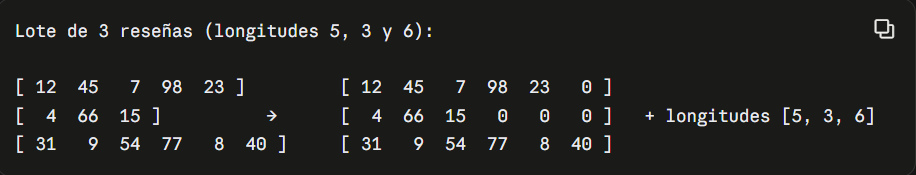

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- 1. Cargar lo preparado en el paso 2 ----------
with open("imdb/preparado.pkl", "rb") as f:
    d = pickle.load(f)
    print("¿que es d?: ",type(d))

itos = d["itos"] # Palabras (tokens str) mas frecuentes
VOCAB = len(itos)
PAD = 0

# ---------- 2. Dataset ----------
class ResenasDataset(Dataset):
    def __init__(self, ids, y):
        self.ids = [torch.tensor(x, dtype=torch.long) for x in ids]   # una secuencia por reseña
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return self.ids[i], self.y[i]

ds_tr = ResenasDataset(d["ids_tr"], d["y_tr"])
ds_va = ResenasDataset(d["ids_va"], d["y_va"])
ds_te = ResenasDataset(d["ids_te"], d["y_te"])

# ---------- 3. Función de apilado con padding ----------
"""
- pad_sequence(seqs, batch_first=True, padding_value=0) apila una lista de tensores 1D de longitudes distintas 
en uno [B, L_max], rellenando con el valor indicado. Con batch_first=True la dimensión del lote va primero, 
igual que en todos los modelos anteriores. Por defecto sería [L, B].

- zip(*batch) transpone la lista de parejas [(seq1, y1), (seq2, y2), ...] en dos tuplas: (seq1, seq2, ...) 
y (y1, y2, ...). Es el mismo operador * que usamos con nn.Sequential(*capas).
"""

def collate(batch):
    seqs, ys = zip(*batch)                                      # separa secuencias y etiquetas
    lengths = torch.tensor([len(s) for s in seqs])              # longitudes reales [B]
    x = pad_sequence(seqs, batch_first=True, padding_value=PAD) # [B, L_max_del_lote]
    return x, lengths, torch.stack(ys)

# ---------- 4. DataLoaders ----------
train_loader = DataLoader(ds_tr, batch_size=64, shuffle=True, collate_fn=collate)
val_loader = DataLoader(ds_va, batch_size=256, collate_fn=collate)
test_loader = DataLoader(ds_te, batch_size=256, collate_fn=collate)
print(len(train_loader), len(val_loader), len(test_loader))

Comprobaciones:

In [ ]:
# ---------- Formas y tipos ----------
x, lengths, y = next(iter(train_loader))
print(x.shape, x.dtype, x[:9])               # torch.Size([64, L]) torch.int64
print(lengths.shape, lengths.dtype)   # torch.Size([64])    torch.int64
print(y.shape, y.dtype)               # torch.Size([64])    torch.float32
print("Longitudes del lote:", lengths[:10].tolist())

# ---------- El padding está al final y es solo ceros ----------
i = lengths.argmin()
print("Reseña más corta del lote:", x[i, : lengths[i] + 3].tolist())   # ... y luego ceros

mascara = x != PAD                                                    # True donde hay palabra real
print("Palabras reales por reseña == longitudes:", torch.equal(mascara.sum(1), lengths))

# ---------- Qué pasaría con el DataLoader normal ----------
try:
    next(iter(DataLoader(ds_tr, batch_size=4)))
except RuntimeError as e:
    print("Error esperado:", str(e)[:90])

El relleno no ensucia el resultado, porque la LSTM lo ignorará gracias a lengths, pero sí tiene un coste. La solución clásica es agrupar por longitud (bucketing): formar los lotes con reseñas de longitud parecida, de modo que el relleno de cada lote sea pequeño.

#### Mejora opcional: lotes por longitud

In [ ]:
class BucketSampler(Sampler):
    """Agrupa reseñas de longitud parecida en el mismo lote, y baraja el orden de los lotes."""
    def __init__(self, longitudes, batch_size, chunk=50, shuffle=True):
        self.lon, self.bs, self.chunk, self.shuffle = longitudes, batch_size, chunk, shuffle

    def __iter__(self):
        idx = list(range(len(self.lon)))
        if self.shuffle:
            random.shuffle(idx)                                   # 1. mezcla global
        tam = self.bs * self.chunk
        lotes = []
        for i in range(0, len(idx), tam):
            trozo = sorted(idx[i:i + tam], key=lambda j: self.lon[j])        # 2. ordena cada trozo por longitud
            lotes += [trozo[k:k + self.bs] for k in range(0, len(trozo), self.bs)]
        if self.shuffle:
            random.shuffle(lotes)                                 # 3. mezcla el orden de los lotes
        yield from lotes

    def __len__(self):
        return math.ceil(len(self.lon) / self.bs)

lon_tr = [len(s) for s in ds_tr.ids]
train_loader_b = DataLoader(ds_tr, batch_sampler=BucketSampler(lon_tr, 64), collate_fn=collate)

def fraccion_padding(loader, n_lotes=100):
    reales, total = 0, 0
    for k, (x, lengths, _) in enumerate(loader):
        if k == n_lotes:
            break
        reales += lengths.sum().item()      # palabras reales del lote
        total += x.numel()                  # tamaño total del tensor (reales + relleno)
    return 1 - reales / total

print(f"Padding con lotes aleatorios: {fraccion_padding(train_loader):.1%}")
print(f"Padding con lotes agrupados por longitud: {fraccion_padding(train_loader_b):.1%}")

## Paso 4: el modelo (Embedding + LSTM bidireccional)

La idea

La red recibe una reseña como una lista de enteros ([12, 45, 7, ...]) y debe devolver un logit: positiva o negativa. Lo hace en tres fases:

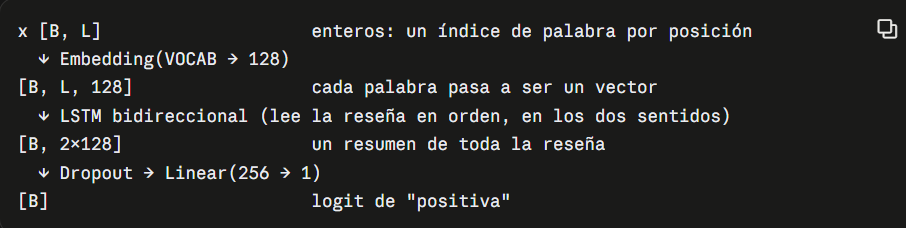

### Fase 1: el Embedding de palabras

Es la misma idea que los embeddings de Title o Sex en Titanic, a otra escala. nn.Embedding(25002, 128) es una tabla de 25.002 filas (una por palabra del vocabulario) y 128 columnas. Dado el índice de una palabra, devuelve su fila:

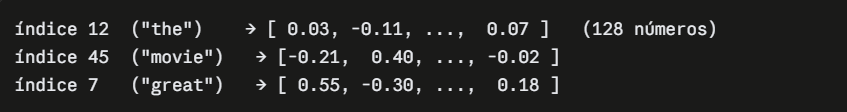

Los números empiezan siendo aleatorios y se aprenden durante el entrenamiento, igual que los pesos de una capa Linear. Al final, palabras que se usan en contextos parecidos (“great”, “excellent”) tienden a tener vectores parecidos. Compara con la alternativa one-hot: un vector de 25.002 ceros con un único 1 no dice nada sobre qué palabras se parecen entre sí, y un vector denso de 128 números sí puede.

En Titanic usamos 2-3 dimensiones para 3-5 categorías. Aquí son 128 para 25.000 palabras, porque el significado de una palabra tiene muchos más matices que el de un puerto de embarque.

padding_idx=0: la fila 0 (<'pad'>) se inicializa a ceros y no recibe gradiente, así que se queda a cero siempre. Así el relleno no aporta señal.

### Fase 2: la LSTM

Una LSTM lee la secuencia palabra a palabra, manteniendo un vector de “memoria” que va actualizando. En cada palabra, unas pequeñas puertas aprendidas deciden:

* qué olvidar de lo que había leído,
* qué añadir de la palabra actual,
* qué mostrar como salida.

Después de la última palabra, ese vector de memoria (el estado oculto final, h_n) es un resumen de la reseña, y es lo que usaremos para clasificar. Una RNN simple se olvida de lo leído al principio; las puertas de la LSTM le permiten conservar información durante muchas palabras.

Bidireccional significa dos LSTM independientes, una que lee de izquierda a derecha y otra de derecha a izquierda. Concatenamos sus estados finales. Ayuda porque:

* La LSTM hacia delante termina con las últimas palabras, que suelen traer el veredicto (“...overall, a waste of time”).
* La LSTM hacia atrás termina con las primeras, y cada una tiene mejor memoria de lo que ha leído más recientemente.

### Fase 3: el problema del padding

Si metiéramos el tensor relleno directamente, la LSTM leería los ceros de las reseñas cortas, y su estado final sería el de “la reseña seguida de cientos de palabras vacías”. Para evitarlo usamos pack_padded_sequence, que le dice a la LSTM la longitud real de cada reseña. La LSTM se detiene en la última palabra real, y su estado final es el correcto.

In [ ]:
class LSTMClasificador(nn.Module):
    def __init__(self, vocab, emb_dim=128, hidden=128, capas=1,
                 dropout=0.4, bidireccional=True, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab, emb_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=capas, batch_first=True,
                            bidirectional=bidireccional,
                            dropout=dropout if capas > 1 else 0.0)
        self.bidireccional = bidireccional
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidireccional else 1), 1)

    """ pack_padded_sequence(e, lengths.cpu(), ...): empaqueta el lote de forma que la LSTM procese cada reseña 
    solo hasta su longitud real. lengths debe estar en CPU, y por eso lo dejamos así en el collate. 
    Con enforce_sorted=False, PyTorch ordena internamente por longitud y devuelve el resultado en el orden 
    original del lote, así que no hay que preocuparse del orden. 
    
    _, (h_n, _) = self.lstm(packed): la LSTM devuelve tres cosas: las salidas de cada paso (las ignoramos), 
    el estado oculto final h_n y el estado de celda final (también lo ignoramos). Solo usamos h_n.
    
    Dos Dropout: uno sobre los embeddings y otro antes de la capa final. El dropout propio de nn.LSTM solo actúa entre 
    capas apiladas, así que con 1 capa no hace nada, y por eso lo ponemos a mano. Con capas=1 y dropout>0, PyTorch 
    avisaría con un warning, y por eso la condición if capas > 1."""

    def forward(self, x, lengths):
        e = self.dropout(self.embedding(x))                           # [B, L, E]
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)                               # h_n: [capas*dirs, B, H]
        if self.bidireccional:
            h = torch.cat([h_n[-2], h_n[-1]], dim=1)                  # [B, 2H]
        else:
            h = h_n[-1]                                               # [B, H]
        return self.fc(self.dropout(h)).squeeze(1)                    # [B]

model = LSTMClasificador(VOCAB).to(device)
print(model)
print("Parámetros:", f"{sum(p.numel() for p in model.parameters()):,}")

Comprobaciones:

In [ ]:
x, lengths, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)

with torch.no_grad():
    e = model.embedding(x)
    print("Entrada:   ", tuple(x.shape))                  # (64, L)
    print("Embedding: ", tuple(e.shape))                  # (64, L, 128)
    print("Salida:    ", tuple(model(x, lengths).shape))  # (64,)

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
model.eval()
with torch.no_grad():
    print("Pérdida inicial:", loss_fn(model(x, lengths), y).item())

In [ ]:
model.eval()
corta, larga = ds_tr[0], max((ds_tr[i] for i in range(50)), key=lambda t: len(t[0]))

solo = collate([corta])
junto = collate([corta, larga])                            # corta + larga -> la corta lleva padding

with torch.no_grad():
    p_solo = model(solo[0].to(device), solo[1])
    p_junto = model(junto[0].to(device), junto[1])

print("Longitudes:", len(corta[0]), len(larga[0]))
print("Sola:", p_solo.item(), "| con padding:", p_junto[0].item())
print("¿Iguales?", torch.allclose(p_solo[0], p_junto[0], atol=1e-4))     # True

In [ ]:
m = LSTMClasificador(VOCAB, dropout=0.0).to(device)
opt = torch.optim.Adam(m.parameters(), lr=1e-3)
m.train()
for paso in range(60):
    loss = loss_fn(m(x, lengths), y)
    opt.zero_grad(); loss.backward(); opt.step()
    if paso % 10 == 0 or paso == 59:
        acc = ((m(x, lengths) > 0).float() == y).float().mean().item()
        print(f"paso {paso:2d} | pérdida {loss.item():.4f} | acc {acc:.0%}")

### Una advertencia sobre el entrenamiento

Las LSTM tienen un punto delicado: sus gradientes pueden explotar en secuencias largas (400 pasos). Para evitarlo se usa gradient clipping, que limita el tamaño del gradiente antes de actualizar:

torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)   # entre backward() y step()

## Paso 5: entrenar, evaluar y combatir el sobreajuste.

### Qué cambia respecto a los proyectos anteriores

El bucle es el de siempre (forward, pérdida, backward, paso del optimizador), con tres diferencias:

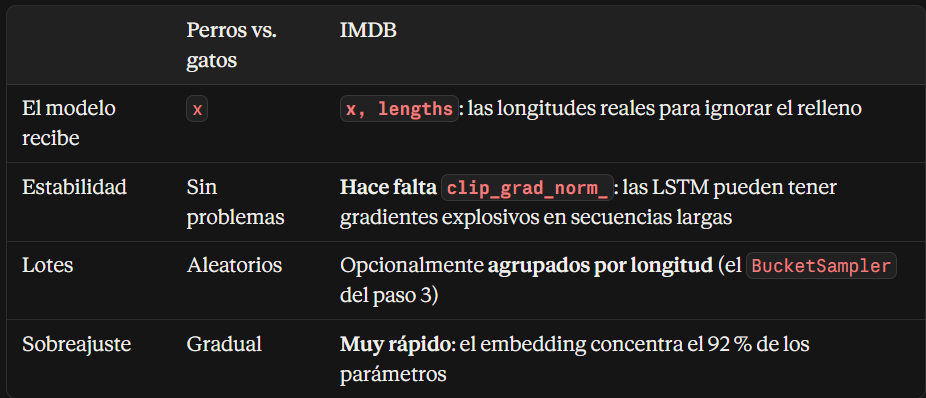

In [ ]:
def entrenar_una_epoca(model, loader, loss_fn, optimizer, clip=1.0):
    model.train()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    for x, lengths, y in loader:
        x, y = x.to(device), y.to(device)                  # lengths se queda en CPU. pack_padded_sequence lo exige así

        pred = model(x, lengths)
        loss = loss_fn(pred, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), clip)  # entre backward() y step() Calcula la norma total 
                                                            # del gradiente y, si supera 1.0, lo reescala para que 
                                                            # valga exactamente 1.0 (la dirección no cambia, solo el tamaño)
        optimizer.step()

        perdida_total += loss.detach() * len(y)
        correctas += ((pred.detach() > 0).float() == y).sum()
        n += len(y)
    return perdida_total.item() / n, correctas.item() / n

@torch.no_grad()
def evaluar(model, loader, loss_fn):
    model.eval()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    for x, lengths, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x, lengths)
        perdida_total += loss_fn(pred, y) * len(y)
        correctas += ((pred > 0).float() == y).sum()
        n += len(y)
    return perdida_total.item() / n, correctas.item() / n

def entrenar(model, train_loader, val_loader, epocas=8, lr=1e-3, weight_decay=1e-4):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor = {"val_loss": float("inf"), "epoca": 0, "estado": None}

    for epoca in range(1, epocas + 1):
        t0 = time.time()
        tl, ta = entrenar_una_epoca(model, train_loader, loss_fn, optimizer)
        vl, va = evaluar(model, val_loader, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)):
            h[k].append(v)
        if vl < mejor["val_loss"]:
            mejor = {"val_loss": vl, "epoca": epoca, "estado": copy.deepcopy(model.state_dict())}
        print(f"Época {epoca}/{epocas} | {time.time() - t0:4.1f} s | "
              f"train: {tl:.4f} ({ta:.1%}) | val: {vl:.4f} ({va:.1%})")
    return h, mejor

def dibujar_historial(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(ep, h["train_loss"], marker="o", label="Train")
    ax1.plot(ep, h["val_loss"], marker="o", label="Validación")
    ax1.set_xlabel("Época"); ax1.set_ylabel("Pérdida"); ax1.set_title("Pérdida por época")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(ep, [a * 100 for a in h["train_acc"]], marker="o", label="Train")
    ax2.plot(ep, [a * 100 for a in h["val_acc"]], marker="o", label="Validación")
    ax2.axhline(50, color="gray", linestyle="--", label="Azar (50 %)")
    ax2.set_xlabel("Época"); ax2.set_ylabel("Precisión (%)"); ax2.set_title("Precisión por época")
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

# ---------- Entrenar ----------
torch.manual_seed(0)
model = LSTMClasificador(VOCAB).to(device)
historial, mejor = entrenar(model, train_loader_b, val_loader, epocas=8)   # train_loader_b: lotes por longitud
print(f"Mejor época por pérdida de validación: {mejor['epoca']}")

torch.save(mejor["estado"], "lstm_base.pt")
dibujar_historial(historial)

In [ ]:
# ¿Cuánto cambian los vectores de palabras raras vs. frecuentes?
emb = model.embedding.weight.detach().cpu()
frecuencias = torch.tensor([contador.get(w, 0) for w in itos])        # 'contador' viene del paso 2
raras = (frecuencias >= 5) & (frecuencias <= 15)
comunes = frecuencias > 1000
print("Norma media del vector, palabras raras: ", emb[raras].norm(dim=1).mean().item())
print("Norma media del vector, palabras comunes:", emb[comunes].norm(dim=1).mean().item())

## Paso 6. Mejoras y transformers.

### Paso 6.1: entrenar mejor el mismo modelo.

#### La idea es que el learning rate suba al principio (warm-up) y baje suave hasta casi cero. Así los primeros pasos son estables y los últimos afinan, lo que debería calmar el ruido de la pérdida de validación. Son dos cambios pequeños en tus funciones.

En entrenar_una_epoca, añade el parámetro scheduler y llámalo tras optimizer.step():

def entrenar_una_epoca(model, loader, loss_fn, optimizer, scheduler=None, clip=1.0):    
    ...     
        optimizer.step()        
        if scheduler is not None:       
            scheduler.step()      # OneCycleLR se actualiza en cada LOTE, no en cada época      
    ...     

En entrenar, crea el scheduler y pásalo:

def entrenar(model, train_loader, val_loader, epocas=15, lr=2e-3, weight_decay=1e-4):       
    loss_fn = nn.BCEWithLogitsLoss()        
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)     
    scheduler = torch.optim.lr_scheduler.OneCycleLR(        
        optimizer, max_lr=lr, total_steps=epocas * len(train_loader))   # nº total de pasos de optimizador      
    ...     
        tl, ta = entrenar_una_epoca(model, train_loader, loss_fn, optimizer, scheduler)     
    ...     

#### Además aumentamos las épocas.

In [ ]:
def entrenar_una_epoca(model, loader, loss_fn, optimizer, scheduler=None, clip=1.0):
    model.train()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    for x, lengths, y in loader:
        x, y = x.to(device), y.to(device)                  # lengths se queda en CPU. pack_padded_sequence lo exige así

        pred = model(x, lengths)
        loss = loss_fn(pred, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), clip)  # entre backward() y step() Calcula la norma total 
                                                            # del gradiente y, si supera 1.0, lo reescala para que 
                                                            # valga exactamente 1.0 (la dirección no cambia, solo el tamaño)
        optimizer.step()
        if scheduler is not None:
            scheduler.step()        # OneCycleLR se actualiza en cada LOTE, no en cada época

        perdida_total += loss.detach() * len(y)
        correctas += ((pred.detach() > 0).float() == y).sum()
        n += len(y)
    return perdida_total.item() / n, correctas.item() / n

@torch.no_grad()
def evaluar(model, loader, loss_fn):
    model.eval()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    for x, lengths, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x, lengths)
        perdida_total += loss_fn(pred, y) * len(y)
        correctas += ((pred > 0).float() == y).sum()
        n += len(y)
    return perdida_total.item() / n, correctas.item() / n

def entrenar(model, train_loader, val_loader, epocas=8, lr=1e-3, weight_decay=1e-4):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, total_steps=epocas * len(train_loader))   # nº total de pasos de optimizador


    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor = {"val_loss": float("inf"), "epoca": 0, "estado": None}

    for epoca in range(1, epocas + 1):
        t0 = time.time()
        tl, ta = entrenar_una_epoca(model, train_loader, loss_fn, optimizer, scheduler)
        vl, va = evaluar(model, val_loader, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)):
            h[k].append(v)
        if vl < mejor["val_loss"]:
            mejor = {"val_loss": vl, "epoca": epoca, "estado": copy.deepcopy(model.state_dict())}
        print(f"Época {epoca}/{epocas} | {time.time() - t0:4.1f} s | "
              f"train: {tl:.4f} ({ta:.1%}) | val: {vl:.4f} ({va:.1%})")
    return h, mejor

def dibujar_historial(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(ep, h["train_loss"], marker="o", label="Train")
    ax1.plot(ep, h["val_loss"], marker="o", label="Validación")
    ax1.set_xlabel("Época"); ax1.set_ylabel("Pérdida"); ax1.set_title("Pérdida por época")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(ep, [a * 100 for a in h["train_acc"]], marker="o", label="Train")
    ax2.plot(ep, [a * 100 for a in h["val_acc"]], marker="o", label="Validación")
    ax2.axhline(50, color="gray", linestyle="--", label="Azar (50 %)")
    ax2.set_xlabel("Época"); ax2.set_ylabel("Precisión (%)"); ax2.set_title("Precisión por época")
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

# ---------- Entrenar ----------
torch.manual_seed(0)
model = LSTMClasificador(VOCAB).to(device)
historial, mejor = entrenar(model, train_loader_b, val_loader, epocas=15)   # train_loader_b: lotes por longitud
print(f"Mejor época por pérdida de validación: {mejor['epoca']}")

torch.save(mejor["estado"], "lstm_6_1.pt")
dibujar_historial(historial)

### Paso 6.2: truncar con principio y final

Tu MAX_LEN = 400 se queda con las primeras 400 palabras. Pero en las reseñas largas el veredicto suele estar al final (“overall, a waste of time”). La alternativa es guardar 100 palabras del principio y 300 del final, con el mismo coste computacional y el mismo vocabulario. Solo cambia codificar:

In [ ]:
HEAD, TAIL = 100, 300                       # 100 + 300 = MAX_LEN

def codificar_ht(tokens):
    if len(tokens) > MAX_LEN:
        tokens = tokens[:HEAD] + tokens[-TAIL:]
    ids = [stoi.get(w, UNK) for w in tokens]
    return ids if ids else [UNK]

print(f"Reseñas truncadas: {np.mean([len(t) > MAX_LEN for t in tok_tr]):.1%}")  # cuántas se ven afectadas

ids_tr2 = [codificar_ht(t) for t in tok_tr]
ids_va2 = [codificar_ht(t) for t in tok_va]

ds_tr2, ds_va2 = ResenasDataset(ids_tr2, d["y_tr"]), ResenasDataset(ids_va2, d["y_va"])
lon_tr2 = [len(s) for s in ds_tr2.ids]
train_loader_b2 = DataLoader(ds_tr2, batch_sampler=BucketSampler(lon_tr2, 64), collate_fn=collate)
val_loader2 = DataLoader(ds_va2, batch_size=256, collate_fn=collate)

random.seed(0); torch.manual_seed(0)      # BucketSampler usa random de Python, no el de torch
model = LSTMClasificador(VOCAB).to(device)
historial, mejor = entrenar(model, train_loader_b2, val_loader2, epocas=15)
torch.save(mejor["estado"], "lstm_6_2.pt")
dibujar_historial(historial)

### Paso 6.3: embeddings preentrenados (GloVe)

GloVe son vectores de palabras entrenados con ~6.000 millones de tokens de Wikipedia y noticias. En lugar de empezar con 3,2 M de números aleatorios, la tabla arranca ya con “great” cerca de “excellent”. Así la LSTM se dedica a combinar significados y no a descubrirlos.

Descarga glove.6B.zip de la página de Stanford GloVe (~800 MB), descomprime glove.6B.100d.txt en tu carpeta imdb/ y ejecuta:

In [ ]:
# ---------- 1. Leer GloVe (solo las palabras de NUESTRO vocabulario) ----------
EMB_DIM = 100
glove = {}
with open("imdb/glove.6B.100d.txt", encoding="utf-8") as f:
    for linea in f:
        palabra, *valores = linea.rstrip().split(" ")
        if palabra in stoi:
            glove[palabra] = np.asarray(valores, dtype=np.float32)

# ---------- 2. Matriz de embeddings alineada con nuestros índices ----------
std = np.stack(list(glove.values())).std()
matriz = np.random.normal(0, std, (VOCAB, EMB_DIM)).astype(np.float32)  # sin GloVe: aleatorio, a la MISMA escala
for w, v in glove.items():
    matriz[stoi[w]] = v
matriz[PAD] = 0

# ---------- 3. Cobertura: ¿cuántas palabras encontró? ----------
tot = sum(contador[w] for w in itos[2:])
print(f"Palabras del vocabulario con GloVe: {len(glove) / VOCAB:.1%}")
print(f"Cobertura ponderada por frecuencia: {sum(contador[w] for w in glove) / tot:.1%}")
faltan = [w for w in itos[2:] if w not in glove][:15]
print("Frecuentes SIN GloVe:", faltan)

Mira bien esa última línea antes de entrenar. GloVe separa “don’t” en do + n't, y nuestro tokenizador lo deja en un solo token, así que esas palabras (muy cargadas de sentimiento: “don’t”, “isn’t”, “wasn’t”) se quedarán sin vector. Lo normal es que la cobertura ponderada sea alta, pero comprueba cuáles son las frecuentes que faltan. Si te parece un problema, tenemos dos opciones: arreglar el tokenizador o dejarlo como está, ya que esas palabras seguirán aprendiéndose con fine-tuning.

Ahora, el modelo. Solo añadimos dos parámetros a LSTMClasificador:

In [ ]:
class LSTMClasificador(nn.Module):
    def __init__(self, vocab, emb_dim=128, hidden=128, capas=1,
                 dropout=0.4, bidireccional=True, pad_idx=0, emb_preentrenado=None, congelar=False):
        super().__init__()
        self.embedding = nn.Embedding(vocab, emb_dim, padding_idx=pad_idx)
        if emb_preentrenado is not None:
            self.embedding.weight.data.copy_(torch.from_numpy(emb_preentrenado))
            self.embedding.weight.requires_grad = not congelar     # congelar = no se actualiza
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=capas, batch_first=True,
                            bidirectional=bidireccional,
                            dropout=dropout if capas > 1 else 0.0)
        self.bidireccional = bidireccional
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidireccional else 1), 1)

    """ pack_padded_sequence(e, lengths.cpu(), ...): empaqueta el lote de forma que la LSTM procese cada reseña 
    solo hasta su longitud real. lengths debe estar en CPU, y por eso lo dejamos así en el collate. 
    Con enforce_sorted=False, PyTorch ordena internamente por longitud y devuelve el resultado en el orden 
    original del lote, así que no hay que preocuparse del orden. 
    
    _, (h_n, _) = self.lstm(packed): la LSTM devuelve tres cosas: las salidas de cada paso (las ignoramos), 
    el estado oculto final h_n y el estado de celda final (también lo ignoramos). Solo usamos h_n.
    
    Dos Dropout: uno sobre los embeddings y otro antes de la capa final. El dropout propio de nn.LSTM solo actúa entre 
    capas apiladas, así que con 1 capa no hace nada, y por eso lo ponemos a mano. Con capas=1 y dropout>0, PyTorch 
    avisaría con un warning, y por eso la condición if capas > 1."""

    def forward(self, x, lengths):
        e = self.dropout(self.embedding(x))                           # [B, L, E]
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)                               # h_n: [capas*dirs, B, H]
        if self.bidireccional:
            h = torch.cat([h_n[-2], h_n[-1]], dim=1)                  # [B, 2H]
        else:
            h = h_n[-1]                                               # [B, H]
        return self.fc(self.dropout(h)).squeeze(1)                    # [B]

model = LSTMClasificador(VOCAB).to(device)
print(model)
print("Parámetros:", f"{sum(p.numel() for p in model.parameters()):,}")

Comparamos dos variantes:

In [ ]:
# A) GloVe + fine-tuning: los vectores arrancan "buenos" pero se siguen ajustando
random.seed(0); torch.manual_seed(0)
model_A = LSTMClasificador(VOCAB, emb_dim=EMB_DIM, emb_preentrenado=matriz).to(device)
hist_A, mejor_A = entrenar(model_A, train_loader_b2, val_loader2, epocas=15)

# B) GloVe congelado: la tabla no se toca
random.seed(0); torch.manual_seed(0)
model_B = LSTMClasificador(VOCAB, emb_dim=EMB_DIM, emb_preentrenado=matriz, congelar=True).to(device)
print("Parámetros entrenables:", f"{sum(p.numel() for p in model_B.parameters() if p.requires_grad):,}")
hist_B, mejor_B = entrenar(model_B, train_loader_b2, val_loader2, epocas=15) # Con GloVe congelado, el modelo tiene 
                                                                             # unos 0,25 M de parámetros entrenables frente a 3,4 M, así que debería sobreajustar menos.

A sobreajusta rápido. Después de la época 6 la pérdida de val sube (0,239 → 0,360) mientras train llega al 98,4 %. Tienes 3,4 M de parámetros, y la tabla de embeddings, que ahora arranca bien, memoriza las reseñas de train. Ese es el nuevo cuello de botella, y ya no es la representación de las palabras.

B subajusta. Con solo 236k parámetros entrenables, train (89,8 %) queda igual que val (89,9 %) y la precisión se estanca. Congelar demasiado limita el modelo. Un detalle interesante: la pérdida de B (0,246) es casi tan buena como la de A (0,239) aunque su precisión sea 1,4 puntos menor. B es más prudente en sus predicciones y A tiende a ser demasiado seguro.

Las contracciones. Se cumplió lo que anticipé: “don’t”, “isn’t”, “wasn’t”, “can’t”, “couldn’t”... no tienen vector GloVe. La cobertura por frecuencia es 98,2 %, pero precisamente se pierden las palabras de negación. En A esos vectores se aprenden desde cero, pero en B quedan fijos y aleatorios, y probablemente eso explique parte de su desventaja (es una hipótesis, no la he comprobado).

### Paso 6.3b (opcional): arreglar el tokenizador

GloVe sigue la tokenización estilo Penn Treebank: “don’t” es do + n't, “it’s” es it + 's. Si tokenizamos igual, el modelo reutiliza el vector preentrenado de n't, que ya significa negación. Es un cambio de una línea, aunque obliga a rehacer los datos. Lo hago ahora porque todo lo posterior depende del vocabulario.

In [ ]:
# Sustituye RE_TOKEN (el resto de la función tokenizar queda igual)
RE_TOKEN = re.compile(r"[a-z0-9]+(?=n't)|n't|'(?:s|m|d|ll|re|ve)\b|[a-z0-9]+|[!?]")

print(tokenizar("I don't think it's great, can't say I'm sure!"))
# ['i', 'do', "n't", 'think', 'it', "'s", 'great', 'ca', "n't", 'say', 'i', "'m", 'sure', '!']

# ---------- 1. Re-tokenizamos las reseñas ----------
tok_tr = [tokenizar(t) for t in df_tr["review"]]
tok_va = [tokenizar(t) for t in df_va["review"]]
tok_te = [tokenizar(t) for t in df_te["review"]]

contador = collections.Counter(w for toks in tok_tr for w in toks)

# ---------- 2. Creamos el diccionario (con las palabras mas frecuentes) ----------
frecuentes = [w for w, c in contador.most_common(MAX_VOCAB) if c >= MIN_FREQ] # Lista de strigns con los tokens mas frecuentes

PAD, UNK = 0, 1
itos = ["<pad>", "<unk>"] + frecuentes              # índice -> palabra
stoi = {w: i for i, w in enumerate(itos)}           # palabra -> índice
print("Tamaño del vocabulario:", len(itos))
print(list(stoi.items())[:10]) # Primeros 10 elementos del diccionario vocabulario

# ---------- 3. Codificamos con el diccionario las reseñas ----------
MAX_LEN = 400

ids_tr2 = [codificar_ht(t) for t in tok_tr] # t es una reseña tokenizada dentro de la lista (de listas) tok_tr con todas las reseñas

num_UNK = sum(token == UNK for lis in ids_tr for token in lis)
print(f"Ratio de UNKs: {num_UNK/len(ids_tr):.2f} UNKs/reseña")

ids_va2 = [codificar_ht(t) for t in tok_va]
ids_te2 = [codificar_ht(t) for t in tok_te]
# ids_xx son listas de listas, donde ids_tr[i] = lista(reseña codificada) = [0,34,7584,32,...]

y_tr, y_va, y_te = df_tr["label"].values, df_va["label"].values, df_te["label"].values

# ---------- 4. Guardamos las reseñas codificadas junto con sus etiquetas y las palabras mas frecuentes ----------
with open("imdb/preparado2.pkl", "wb") as f:
    pickle.dump(dict(itos=itos, ids_tr=ids_tr2, ids_va=ids_va2, ids_te=ids_te2,
                     y_tr=y_tr, y_va=y_va, y_te=y_te), f)

with open("imdb/preparado2.pkl", "rb") as f:
    d = pickle.load(f)
    print("¿que es d?: ",type(d))

itos = d["itos"] # Palabras (tokens str) mas frecuentes
VOCAB = len(itos)
PAD = 0

# ---------- 5. Leer GloVe (solo las palabras de NUESTRO vocabulario) ----------
EMB_DIM = 100
glove = {}
with open("imdb/glove.6B.100d.txt", encoding="utf-8") as f:
    for linea in f:
        palabra, *valores = linea.rstrip().split(" ")
        if palabra in stoi:
            glove[palabra] = np.asarray(valores, dtype=np.float32)

print("Golve:")
print(list(glove)[:2])

# ---------- 6. Matriz de embeddings alineada con nuestros índices ----------
std = np.stack(list(glove.values())).std()
matriz = np.random.normal(0, std, (VOCAB, EMB_DIM)).astype(np.float32)  # sin GloVe: aleatorio, a la MISMA escala
for w, v in glove.items():          # <unk> (índice 1): tampoco tiene vector en GloVe, así que conserva 
                                    # el valor aleatorio con el que rellenaste toda la matriz (np.random.normal(0, std, ...)). 
                                    # Por eso inicializamos al azar con la misma escala que GloVe (std) y no con N(0,1), para 
                                    # que <unk> y las ~4,4 % palabras sin vector no estén en una escala distinta de las demás
    matriz[stoi[w]] = v         
matriz[PAD] = 0
print(matriz[:2])

# ---------- 7. Cobertura: ¿cuántas palabras encontró? ----------
tot = sum(contador[w] for w in itos[2:])
print(f"Palabras del vocabulario con GloVe: {len(glove) / VOCAB:.1%}")
print(f"Cobertura ponderada por frecuencia: {sum(contador[w] for w in glove) / tot:.1%}")
faltan = [w for w in itos[2:] if w not in glove][:15]
print("Frecuentes SIN GloVe:", faltan)

# ---------- 8. DataSets ----------
ds_tr = ResenasDataset(d["ids_tr"], d["y_tr"])
ds_va = ResenasDataset(d["ids_va"], d["y_va"])
ds_te = ResenasDataset(d["ids_te"], d["y_te"])


# ---------- 9. DataLoaders ----------
train_loader = DataLoader(ds_tr, batch_size=64, shuffle=True, collate_fn=collate)
val_loader = DataLoader(ds_va, batch_size=256, collate_fn=collate)
test_loader = DataLoader(ds_te, batch_size=256, collate_fn=collate)
print(len(train_loader), len(val_loader), len(test_loader))

# ---------- 10. Entrenar modelo (sin congelar) ----------
random.seed(0); torch.manual_seed(0)
model_A = LSTMClasificador(VOCAB, emb_dim=EMB_DIM, emb_preentrenado=matriz).to(device)
hist_A, mejor_A = entrenar(model_A, train_loader_b2, val_loader2, epocas=15)

## 6.4 Mejora con MeanPool, MaxPool y Atencion.

Ahora mismo tu LSTM lee 400 palabras y se queda con un único vector, el último estado h_n, para clasificar. Todo lo que dijo “terrible” en la palabra 37 tiene que sobrevivir a 360 pasos de la LSTM hasta llegar a ese vector. Pero la LSTM produce además una salida por cada palabra (el _ que descartabas), y ahí hay información que no usamos. Las alternativas son:

- Mean pooling: media de las salidas de todas las palabras reales. Es el “sentimiento promedio” de la reseña.
- Max pooling: para cada una de las 256 dimensiones, el valor máximo a lo largo de la reseña. Funciona como un detector de “¿apareció en algún sitio algo muy negativo?”.
- Atención: la red aprende cuánto pesa cada palabra. Una capa Linear(256, 1) da una puntuación por palabra, un softmax las convierte en pesos que suman 1 y el resumen es la media ponderada: h = Σ pesoᵢ · salidaᵢ. Es la misma idea de la que parten los Transformers.

Los tres tienen un efecto extra: el gradiente llega directamente a cada palabra, sin tener que atravesar toda la secuencia. Por eso suelen entrenar mejor.

Lo único delicado es el padding. Las posiciones de relleno no deben entrar en la media, ni en el máximo, ni en el softmax, y por eso se enmascaran. Es el mismo problema que pack_padded_sequence resolvía antes, y la mask que construimos aquí la reutilizaremos en el Transformer.

In [ ]:
class LSTMPool(nn.Module):
    def __init__(self, vocab, emb_dim=100, hidden=128, dropout=0.4,
                 pooling="attn", pad_idx=0, emb_preentrenado=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab, emb_dim, padding_idx=pad_idx)
        if emb_preentrenado is not None:
            self.embedding.weight.data.copy_(torch.from_numpy(emb_preentrenado))
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.pooling = pooling
        self.attn = nn.Linear(2 * hidden, 1)          # una puntuación por palabra
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden, 1)

    def forward(self, x, lengths):
        e = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, (h_n, _) = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))  # [B, L, 2H]
        mask = (x != PAD).unsqueeze(-1)                                              # [B, L, 1]

        if self.pooling == "last":
            h = torch.cat([h_n[-2], h_n[-1]], dim=1)
        elif self.pooling == "mean":
            h = (out * mask).sum(1) / mask.sum(1)                    # solo palabras reales
        elif self.pooling == "max":
            h = out.masked_fill(~mask, -1e9).max(1).values           # el relleno nunca gana
        elif self.pooling == "attn":
            score = self.attn(out).masked_fill(~mask, -1e9)          # [B, L, 1]
            w = torch.softmax(score, dim=1)                          # pesos: suman 1 por reseña
            self.last_attn = w.detach().squeeze(-1)                  # lo guardamos para inspeccionarlo
            h = (w * out).sum(1)                                     # media ponderada
        return self.fc(self.dropout(h)).squeeze(1)

Antes de entrenar, la misma comprobación de padding de siempre: una reseña sola y con relleno debe dar el mismo resultado, para los tres pooling.

In [ ]:
corta, larga = ds_tr2[0], max((ds_tr2[i] for i in range(50)), key=lambda t: len(t[0]))
solo, junto = collate([corta]), collate([corta, larga])
for pool in ("mean", "max", "attn"):
    m = LSTMPool(VOCAB, pooling=pool, emb_preentrenado=matriz).to(device).eval()
    with torch.no_grad():
        a, b = m(solo[0].to(device), solo[1]), m(junto[0].to(device), junto[1])
    print(pool, "| ¿iguales con padding?", torch.allclose(a[0], b[0], atol=1e-4))   # True x3

Ahora entrena las tres variantes con la misma semilla y los mismos datos. Son ~16 minutos en total:

In [ ]:
res, modelos = {}, {}
for pool in ("mean", "max", "attn"):
    print(f"\n===== pooling: {pool} =====")
    random.seed(0); torch.manual_seed(0)
    m = LSTMPool(VOCAB, pooling=pool, emb_preentrenado=matriz).to(device)
    h, mejor = entrenar(m, train_loader_b2, val_loader2, epocas=15)
    i = mejor["epoca"] - 1
    res[pool] = (h["val_loss"][i], h["val_acc"][i], h["train_acc"][i])
    m.load_state_dict(mejor["estado"]); modelos[pool] = m
    torch.save(mejor["estado"], f"lstm_6_4_{pool}.pt")

print("\n                    val_loss  val_acc  train_acc")
print(f"last (referencia)   0.2585    90.4%    94.6% (época 7)")
for pool, (l, a, ta) in res.items():
    print(f"{pool:<19} {l:.4f}    {a:.1%}    {ta:.1%}")

Y cuando termine, el atractivo del modelo con atención: ver qué palabras mira.

In [ ]:
def ver_atencion(texto, modelo, k=8):
    modelo.eval()
    toks = tokenizar(texto)
    ids = torch.tensor([[stoi.get(w, UNK) for w in toks]]).to(device)
    with torch.no_grad():
        p = torch.sigmoid(modelo(ids, torch.tensor([len(toks)]))).item()
    w = modelo.last_attn[0].cpu()
    top = w.topk(min(k, len(toks)))
    print(f"P(positiva) = {p:.2f}")
    print("Palabras con más peso:", [(toks[i], round(v.item(), 3)) for v, i in zip(top.values, top.indices)])

ver_atencion("I expected a great movie but it was boring and the ending was a complete waste of time!", modelos["attn"])
ver_atencion("Not bad at all, I actually loved the acting even though the plot is thin.", modelos["attn"])

## Paso 6.5: Transformer encoder desde cero

La idea

Una LSTM lee palabra a palabra y arrastra una memoria. La self-attention hace lo contrario: cada palabra mira a todas las demás de la reseña en un solo paso.

1. Cada palabra genera, con tres capas Linear, una query (qué busco), una key (qué ofrezco) y un value (qué información aporto).
2. La puntuación entre dos palabras es q · k / √d. Un softmax la convierte en pesos que suman 1.
3. La nueva representación de cada palabra es la media ponderada de los values de todas las palabras. Así “good” puede absorber que está precedida de “not” sin esperar 300 pasos.
4. Multi-head: se repite todo esto en paralelo con varias cabezas, cada una en un subespacio más pequeño, para que unas se fijen en la sintaxis y otras en el sentimiento, por ejemplo.

La mecánica con una máscara de relleno, a mano y comprobada contra la función de PyTorch:

In [ ]:
B, L, D = 2, 5, 8
q = k = v = torch.randn(B, L, D)
pad = torch.tensor([[0,0,0,1,1],[0,0,0,0,0]], dtype=torch.bool)   # True = relleno

scores = q @ k.transpose(1, 2) / D**0.5                      # [B, L, L]: cuánto mira cada palabra a cada otra
scores = scores.masked_fill(pad[:, None, :], float("-inf"))  # nadie mira al relleno
w = torch.softmax(scores, dim=-1)                            # cada fila suma 1
salida = w @ v                                               # [B, L, D]

print(w[0].round(decimals=2))        # las 2 últimas columnas deben ser 0
print(torch.allclose(salida, F.scaled_dot_product_attention(q, k, v, attn_mask=~pad[:, None, :]), atol=1e-6))

El problema del orden: la atención no sabe en qué posición está cada palabra, así que “not good” y “good not” le parecen iguales. Hay que sumar a cada embedding un vector de posición. Usamos un embedding de posición aprendido (como BERT), con un vector por cada posición 0..399. El artículo original usaba senos y cosenos fijos, y ambas opciones son válidas.

El modelo

Mantengo forward(x, lengths) para que tu entrenar funcione sin cambios. Usa los mismos GloVe de 100 dimensiones (con 4 cabezas de 25) y el mean pooling con máscara que acabamos de ver:

In [ ]:
class TransformerClasificador(nn.Module):
    def __init__(self, vocab, d_model=100, nhead=4, capas=2, ff=256, dropout=0.3,
                 max_len=400, pad_idx=0, emb_preentrenado=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab, d_model, padding_idx=pad_idx)
        if emb_preentrenado is not None:
            self.embedding.weight.data.copy_(torch.from_numpy(emb_preentrenado))
        self.pos = nn.Embedding(max_len, d_model)                  # un vector por posición
        nn.init.normal_(self.pos.weight, std=0.02)
        capa = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=ff, dropout=dropout,
                                          activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(capa, num_layers=capas, norm=nn.LayerNorm(d_model),
                                             enable_nested_tensor=False)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x, lengths=None):
        pad = (x == PAD)                                           # [B, L] True en el relleno
        posiciones = torch.arange(x.size(1), device=x.device)      # [L]
        h = self.dropout(self.embedding(x) + self.pos(posiciones)) # [B, L, D]
        h = self.encoder(h, src_key_padding_mask=pad)              # [B, L, D]
        m = (~pad).unsqueeze(-1)
        h = (h * m).sum(1) / m.sum(1)                              # media solo de palabras reales
        return self.fc(self.dropout(h)).squeeze(1)

Qué hace cada pieza que no conocías:

* norm_first=True (Pre-LN): normaliza antes de cada sub-bloque. Es más estable de entrenar y tolera mejor learning rates altos que el diseño original.
* dim_feedforward: tras la atención, cada palabra pasa por un pequeño MLP (100 → 256 → 100). La atención mezcla información entre palabras y el MLP la procesa dentro de cada una.
* Conexiones residuales: vienen incluidas en la capa. Es la misma idea que en ResNet18, que ya conoces del proyecto de gatos y perros.

Comprobaciones y entrenamiento

La comprobación de padding de siempre: debe dar True.

In [ ]:
model_T = TransformerClasificador(VOCAB, emb_preentrenado=matriz).to(device).eval()
corta, larga = ds_tr2[0], max((ds_tr2[i] for i in range(50)), key=lambda t: len(t[0]))
solo, junto = collate([corta]), collate([corta, larga])
with torch.no_grad():
    a, b = model_T(solo[0].to(device), solo[1]), model_T(junto[0].to(device), junto[1])
print("¿Iguales con padding?", torch.allclose(a[0], b[0], atol=1e-4))
print("Parámetros:", f"{sum(p.numel() for p in model_T.parameters()):,}")

Y a entrenar. Los Transformers son más sensibles al learning rate que las LSTM, así que bajo lr y subo el weight_decay, valores habituales con AdamW. El OneCycle que ya tienes hace de warm-up:

In [ ]:
random.seed(0); torch.manual_seed(0)
model_T = TransformerClasificador(VOCAB, emb_preentrenado=matriz).to(device)
hist_T, mejor_T = entrenar(model_T, train_loader_b2, val_loader2, epocas=10, lr=5e-4, weight_decay=1e-2)
torch.save(mejor_T["estado"], "transformer_6_5.pt")
dibujar_historial(hist_T)

## Paso 6.6: fine-tuning de DistilBERT

La idea

DistilBERT es una versión comprimida de BERT: 6 capas Transformer, vectores de 768 dimensiones y ~66 M de parámetros. Se preentrenó con Wikipedia y miles de libros, con una tarea sencilla: tapar palabras al azar y que el modelo adivine cuáles son. Para acertar necesita entender gramática, hechos, contexto y matices, y eso ya viene en los pesos. Nosotros solo le añadimos una capa final Linear(768, 1) y entrenamos todo el modelo con pocos pasos y un learning rate muy pequeño (~2e-5), para ajustarlo a reseñas sin destruir lo aprendido.

Tres diferencias con lo que has hecho hasta ahora:

1. El tokenizador viene con el modelo. Usa WordPiece: las palabras desconocidas se parten en trozos (“hackenstein” → hack, ##ens, ##tein), así que no existe el <unk> que te costaba 4,23 por reseña. Además, el modelo entiende el contexto: “bank” tiene un vector distinto en “river bank” y en “bank loan”, cosa que GloVe no podía.
2. Se añaden dos tokens especiales: [CLS] al inicio y [SEP] al final. Clasificamos con el vector de salida de [CLS], que el modelo aprende a usar como resumen de la frase.
3. Es un modelo grande (66 M frente a 2-3 M), así que cuesta más tiempo y memoria.

Un detalle que simplifica todo: el [PAD] de DistilBERT también es el índice 0, igual que el tuyo. Así tu collate y tu entrenar siguen valiendo sin cambios.

In [ ]:
# pip install transformers        (ejecútalo en una celda con "!" o en la terminal)
from transformers import AutoTokenizer, AutoModel

NOMBRE = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(NOMBRE)
print("PAD:", tok.pad_token_id, "| CLS:", tok.cls_token_id, "| SEP:", tok.sep_token_id)   # 0 | 101 | 102
print(tok.tokenize("The hackenstein movie wasn't great!"))

* PAD: 0 confirma lo que dije: el relleno de DistilBERT coincide con el tuyo, así que tu collate, ResenasDataset y entrenar valen sin cambios.
* hackenstein → hack + ##enstein es WordPiece: una palabra rara se parte en trozos conocidos en lugar de convertirse en <unk>.
* wasn't → wasn, ', t. Es distinto a tu tokenizador y al de GloVe (was + n't), pero no es un problema. La negación llega a “t” a través del contexto de la frase, y el modelo aprendió en el preentrenamiento a combinar esos tres trozos. Es otra ventaja de que los vectores sean contextuales.

Ahora codificamos las reseñas crudas (solo quitamos el HTML), no las tuyas ya tokenizadas. Uso la misma idea del truncado head+tail del 6.2, y esta vez importa más: con 256 tokens de BERT (~190 palabras), la mayoría de las reseñas no cabe entera.

No tocamos df_te ni el test.

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
PAD = 0                                                 # en DistilBERT el [PAD] también es el 0

# ---------- 1. Cargar y dividir (idéntico al Paso 2) ----------
df = pd.read_csv("imdb/IMDB Dataset.csv").drop_duplicates().reset_index(drop=True)
df["label"] = (df["sentiment"] == "positive").astype(int)

df_tr, df_rest = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=42)
df_va, df_te = train_test_split(df_rest, test_size=0.5, stratify=df_rest["label"], random_state=42)
print(len(df_tr), len(df_va), len(df_te))               # 39665 4958 4959

# ---------- 2. Dataset, collate y BucketSampler (los de los pasos 3) ----------
class ResenasDataset(Dataset):
    def __init__(self, ids, y):
        self.ids = [torch.tensor(x, dtype=torch.long) for x in ids]
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return self.ids[i], self.y[i]

def collate(batch):
    seqs, ys = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])
    x = pad_sequence(seqs, batch_first=True, padding_value=PAD)
    return x, lengths, torch.stack(ys)

class BucketSampler(Sampler):
    """Agrupa reseñas de longitud parecida en el mismo lote, y baraja el orden de los lotes."""
    def __init__(self, longitudes, batch_size, chunk=50, shuffle=True):
        self.lon, self.bs, self.chunk, self.shuffle = longitudes, batch_size, chunk, shuffle
    def __iter__(self):
        idx = list(range(len(self.lon)))
        if self.shuffle:
            random.shuffle(idx)
        tam = self.bs * self.chunk
        lotes = []
        for i in range(0, len(idx), tam):
            trozo = sorted(idx[i:i + tam], key=lambda j: self.lon[j])
            lotes += [trozo[k:k + self.bs] for k in range(0, len(trozo), self.bs)]
        if self.shuffle:
            random.shuffle(lotes)
        yield from lotes
    def __len__(self):
        return math.ceil(len(self.lon) / self.bs)

# ---------- 3. Tokenizador de DistilBERT ----------
NOMBRE = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(NOMBRE)
print("PAD:", tok.pad_token_id, "| CLS:", tok.cls_token_id, "| SEP:", tok.sep_token_id)   # 0 | 101 | 102

# ---------- 4. Codificar las reseñas crudas (solo quitamos el HTML) ----------
RE_HTML = re.compile(r"<[^>]+>")
MAXB, HEAD_B = 256, 64          # 1 [CLS] + 64 del principio + 190 del final + 1 [SEP] = 256

def codificar_bert(textos):
    limpios = [RE_HTML.sub(" ", t) for t in textos]
    salida = []
    for ids in tok(limpios, add_special_tokens=False)["input_ids"]:
        if len(ids) > MAXB - 2:
            ids = ids[:HEAD_B] + ids[-(MAXB - 2 - HEAD_B):]
        salida.append([tok.cls_token_id] + ids + [tok.sep_token_id])
    return salida

ids_tr_b = codificar_bert(df_tr["review"])
ids_va_b = codificar_bert(df_va["review"])
print("Reseñas que no caben enteras:", np.mean([len(x) == MAXB for x in ids_tr_b]).round(3))

# ---------- 5. Datasets y DataLoaders (test sin tocar) ----------
ds_tr_b = ResenasDataset(ids_tr_b, df_tr["label"].values)
ds_va_b = ResenasDataset(ids_va_b, df_va["label"].values)

train_loader_bert = DataLoader(ds_tr_b, batch_sampler=BucketSampler([len(s) for s in ds_tr_b.ids], 32),
                               collate_fn=collate)
val_loader_bert = DataLoader(ds_va_b, batch_size=64, collate_fn=collate)
print("Lotes:", len(train_loader_bert), len(val_loader_bert))

# ---------- 6. Comprobación rápida ----------
x, lengths, y = next(iter(train_loader_bert))
print(x.shape, "| primer token de cada reseña (debe ser 101):", x[:5, 0].tolist(),
      "| etiquetas:", y[:5].tolist())

El modelo

In [ ]:
# ---------- 1. Funciones de entrenamiento (Paso 5 + scheduler del 6.1) ----------
def entrenar_una_epoca(model, loader, loss_fn, optimizer, scheduler=None, clip=1.0):
    model.train()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    for x, lengths, y in loader:
        x, y = x.to(device), y.to(device)

        pred = model(x, lengths)
        loss = loss_fn(pred, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        if scheduler is not None:
            scheduler.step()            # OneCycleLR se actualiza en cada LOTE

        perdida_total += loss.detach() * len(y)
        correctas += ((pred.detach() > 0).float() == y).sum()
        n += len(y)
    return perdida_total.item() / n, correctas.item() / n

@torch.no_grad()
def evaluar(model, loader, loss_fn):
    model.eval()
    perdida_total = torch.zeros((), device=device)
    correctas = torch.zeros((), device=device)
    n = 0
    for x, lengths, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x, lengths)
        perdida_total += loss_fn(pred, y) * len(y)
        correctas += ((pred > 0).float() == y).sum()
        n += len(y)
    return perdida_total.item() / n, correctas.item() / n

def entrenar(model, train_loader, val_loader, epocas=15, lr=2e-3, weight_decay=1e-4):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, total_steps=epocas * len(train_loader))
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor = {"val_loss": float("inf"), "epoca": 0, "estado": None}

    for epoca in range(1, epocas + 1):
        t0 = time.time()
        tl, ta = entrenar_una_epoca(model, train_loader, loss_fn, optimizer, scheduler)
        vl, va = evaluar(model, val_loader, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)):
            h[k].append(v)
        if vl < mejor["val_loss"]:
            mejor = {"val_loss": vl, "epoca": epoca, "estado": copy.deepcopy(model.state_dict())}
        print(f"Época {epoca}/{epocas} | {time.time() - t0:4.1f} s | "
              f"train: {tl:.4f} ({ta:.1%}) | val: {vl:.4f} ({va:.1%})")
    return h, mejor

def dibujar_historial(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(ep, h["train_loss"], marker="o", label="Train")
    ax1.plot(ep, h["val_loss"], marker="o", label="Validación")
    ax1.set_xlabel("Época"); ax1.set_ylabel("Pérdida"); ax1.set_title("Pérdida por época")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(ep, [a * 100 for a in h["train_acc"]], marker="o", label="Train")
    ax2.plot(ep, [a * 100 for a in h["val_acc"]], marker="o", label="Validación")
    ax2.axhline(50, color="gray", linestyle="--", label="Azar (50 %)")
    ax2.set_xlabel("Época"); ax2.set_ylabel("Precisión (%)"); ax2.set_title("Precisión por época")
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

# ---------- 2. Modelo ----------
class DistilBertClasificador(nn.Module):
    def __init__(self, nombre=NOMBRE, dropout=0.2):
        super().__init__()
        self.bert = AutoModel.from_pretrained(nombre)          # pesos preentrenados
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(self.bert.config.dim, 1)           # 768 -> 1

    def forward(self, x, lengths=None):
        mask = (x != PAD)                                      # 1 = palabra real, 0 = relleno
        h = self.bert(input_ids=x, attention_mask=mask).last_hidden_state[:, 0]   # salida de [CLS]
        return self.fc(self.dropout(h)).squeeze(1)

model_B = DistilBertClasificador().to(device)
print("Dispositivo:", device)
print("Parámetros:", f"{sum(p.numel() for p in model_B.parameters()):,}")

# ---------- 3. Comprobaciones antes de entrenar ----------
# a) Padding: la misma reseña sola y con relleno debe dar lo mismo
corta = ds_tr_b[0]
larga = max((ds_tr_b[i] for i in range(50)), key=lambda t: len(t[0]))
solo, junto = collate([corta]), collate([corta, larga])
model_B.eval()
with torch.no_grad():
    a = model_B(solo[0].to(device))
    b = model_B(junto[0].to(device))
print("Longitudes:", len(corta[0]), len(larga[0]),
      "| ¿Iguales con padding?", torch.allclose(a[0], b[0], atol=1e-3))

# b) Pérdida inicial (debería rondar 0,69)
x, lengths, y = next(iter(train_loader_bert))
with torch.no_grad():
    print("Pérdida inicial:", nn.BCEWithLogitsLoss()(model_B(x.to(device)), y.to(device)).item())

Prueba corta para ver cuanto tarda:

In [17]:
sub = torch.utils.data.Subset(ds_tr_b, range(3200))      # 100 lotes de 32
lon = [len(s) for s in sub.dataset.ids[:3200]]
loader_prueba = DataLoader(sub, batch_sampler=BucketSampler(lon, 32), collate_fn=collate)
m_prueba = DistilBertClasificador().to(device)
entrenar(m_prueba, loader_prueba, val_loader_bert, epocas=1, lr=2e-5, weight_decay=1e-2)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Época 1/1 | 43.9 s | train: 0.4731 (75.5%) | val: 0.2935 (88.7%)


({'train_loss': [0.47308643341064455],
  'val_loss': [0.2935075286705199],
  'train_acc': [0.755],
  'val_acc': [0.8870512303348125]},
 {'val_loss': 0.2935075286705199,
  'epoca': 1,
  'estado': OrderedDict([('bert.embeddings.word_embeddings.weight',
                tensor([[-0.0166, -0.0666, -0.0163,  ..., -0.0200, -0.0514, -0.0264],
                        [-0.0132, -0.0673, -0.0161,  ..., -0.0227, -0.0554, -0.0260],
                        [-0.0176, -0.0709, -0.0144,  ..., -0.0246, -0.0596, -0.0232],
                        ...,
                        [-0.0231, -0.0588, -0.0105,  ..., -0.0195, -0.0262, -0.0212],
                        [-0.0490, -0.0561, -0.0047,  ..., -0.0107, -0.0180, -0.0219],
                        [-0.0065, -0.0915, -0.0025,  ..., -0.0151, -0.0504,  0.0460]],
                       device='cuda:0')),
               ('bert.embeddings.position_embeddings.weight',
                tensor([[ 1.7661e-02, -2.5696e-02, -3.6375e-02,  ...,  1.0916e-05,
                

celda del entrenamiento:

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Época 1/3 | 385.0 s | train: 0.3580 (82.3%) | val: 0.1957 (92.5%)
Época 2/3 | 394.2 s | train: 0.1658 (93.9%) | val: 0.1780 (93.8%)
Época 3/3 | 393.6 s | train: 0.0872 (97.2%) | val: 0.2119 (93.8%)


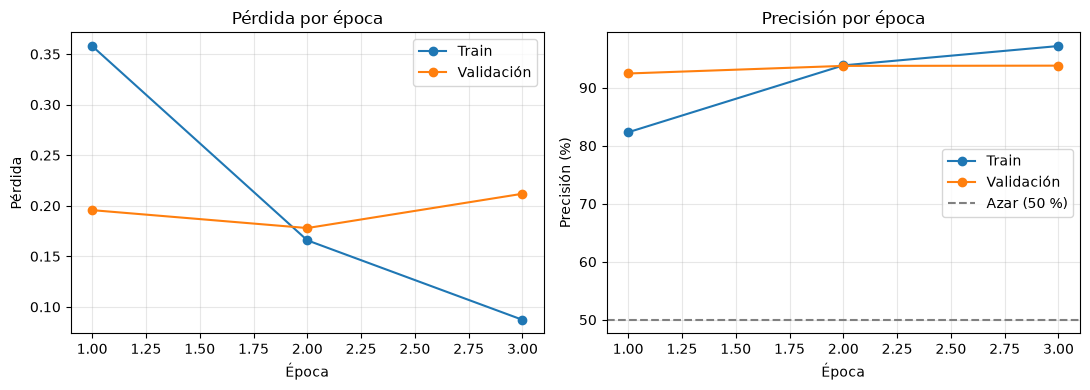

In [20]:
import gc
for nombre in ("m_prueba", "model_B"):
    if nombre in globals():
        del globals()[nombre]
gc.collect(); torch.cuda.empty_cache()

random.seed(0); torch.manual_seed(0)
model_B = DistilBertClasificador().to(device)
hist_B, mejor_B = entrenar(model_B, train_loader_bert, val_loader_bert,
                           epocas=3, lr=2e-5, weight_decay=1e-2)
torch.save(mejor_B["estado"], "distilbert_6_6.pt")
dibujar_historial(hist_B)

## 7. Test

In [21]:
# ---------- 1. DistilBERT: cargar la MEJOR época (la 2), no la última ----------
model_B.load_state_dict(mejor_B["estado"])
# Si reiniciaste el kernel:
# model_B = DistilBertClasificador().to(device)
# model_B.load_state_dict(torch.load("distilbert_6_6.pt"))

ids_te_b = codificar_bert(df_te["review"])
ds_te_b = ResenasDataset(ids_te_b, df_te["label"].values)
test_loader_bert = DataLoader(ds_te_b, batch_size=64, collate_fn=collate)   # sin barajar: mismo orden que df_te

@torch.no_grad()
def predecir_probs(model, loader):
    model.eval()
    return torch.cat([torch.sigmoid(model(x.to(device), lengths)).cpu()
                      for x, lengths, _ in loader]).numpy()

y_te = df_te["label"].values
p_bert = predecir_probs(model_B, test_loader_bert)

# ---------- 2. Baseline TF-IDF: reentrenado en el MISMO df_tr y evaluado en el MISMO df_te ----------
vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2)
X_tr = vec.fit_transform(df_tr["review"])
X_te = vec.transform(df_te["review"])
clf = LogisticRegression(max_iter=1000).fit(X_tr, df_tr["label"])
p_base = clf.predict_proba(X_te)[:, 1]

# ---------- 3. Resultados con intervalo de confianza (~95 %) ----------
def resumen(nombre, p):
    acc = ((p > 0.5) == y_te).mean()
    pc = np.clip(p, 1e-7, 1 - 1e-7)
    loss = -(y_te * np.log(pc) + (1 - y_te) * np.log(1 - pc)).mean()
    ic = 1.96 * np.sqrt(acc * (1 - acc) / len(y_te))
    print(f"{nombre:<22} acc {acc:.2%} ± {ic:.2%} | pérdida {loss:.4f}")

print("Tamaño del test:", len(y_te))
resumen("TF-IDF + reg. logística", p_base)
resumen("DistilBERT (época 2)", p_bert)

np.save("probs_te_bert.npy", p_bert)     # los guardamos para el análisis de errores
np.save("probs_te_base.npy", p_base)

Tamaño del test: 4959
TF-IDF + reg. logística acc 90.42% ± 0.82% | pérdida 0.2799
DistilBERT (época 2)   acc 94.11% ± 0.66% | pérdida 0.1641
